# 04 — Proposed improvement: fixed-budget reference augmentation
**Completed ablation:** 900 verified evaluations; 15 categories, three fixed choices of one reference, four banks, five conditions. The augmentation is exploratory, not independently confirmatory. See [protocol](../protocols/reference_augmentation.md).

**RQ3 (Chapter 8).** The four memory banks share one normal reference per run and the same number of stored embeddings. The rotation-only bank is the matched comparator; archive parity was evaluated separately. This notebook analyzes the verified archived metrics rather than rerunning inference.

## 1. Verify the matched experimental design
Each configuration stores exactly 8,192 patch embeddings. The reference identity and patch budget match across the four banks.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
REPORT = ROOT / 'reports'
FIG = REPORT / 'publication_assets/figures'
conditions = ['original','brightness_085','brightness_070','blur_075','blur_150']
variants = ['rotation_only','brightness','blur','combined']
metrics = ['image_auroc','image_ap','image_f1max','pixel_auroc','pixel_f1max','pixel_aupro']
runs = pd.read_csv(REPORT/'reference_augmentation/per_run.csv')
macro = pd.read_csv(REPORT/'reference_augmentation/macro.csv')
cat = pd.read_csv(REPORT/'reference_augmentation/per_category.csv')
key = ['category','seed','condition']
assert len(runs)==900 and not runs.duplicated(key+['variant']).any()
assert set(runs.groupby(key).size())=={4}
assert runs.category.nunique()==15 and set(runs.seed)=={0,1,2}
assert set(runs.condition)==set(conditions) and set(runs.variant)==set(variants)
assert runs.bank_patches.eq(8192).all()
assert runs.groupby(key).reference_sha256.nunique().eq(1).all()
np.testing.assert_allclose(runs.groupby(['variant','condition'])[metrics].mean().sort_index(),
    macro.set_index(['variant','condition'])[metrics].sort_index(),rtol=0,atol=1e-12)
print('Verified:',len(runs),'evaluations; matched bank size and reference hashes.')


Verified: 900 evaluations; matched bank size and reference hashes.


## 2. Primary endpoints across all conditions
Absolute metrics in percent; paired gains in percentage points.

variant,rotation_only,brightness,blur,combined
condition,,,,
original,96.52,96.45,96.60,96.52
brightness_085,96.62,96.54,96.69,96.59
brightness_070,96.46,96.40,96.51,96.43
blur_075,95.86,95.83,96.18,96.03
blur_150,93.44,93.26,94.98,94.88


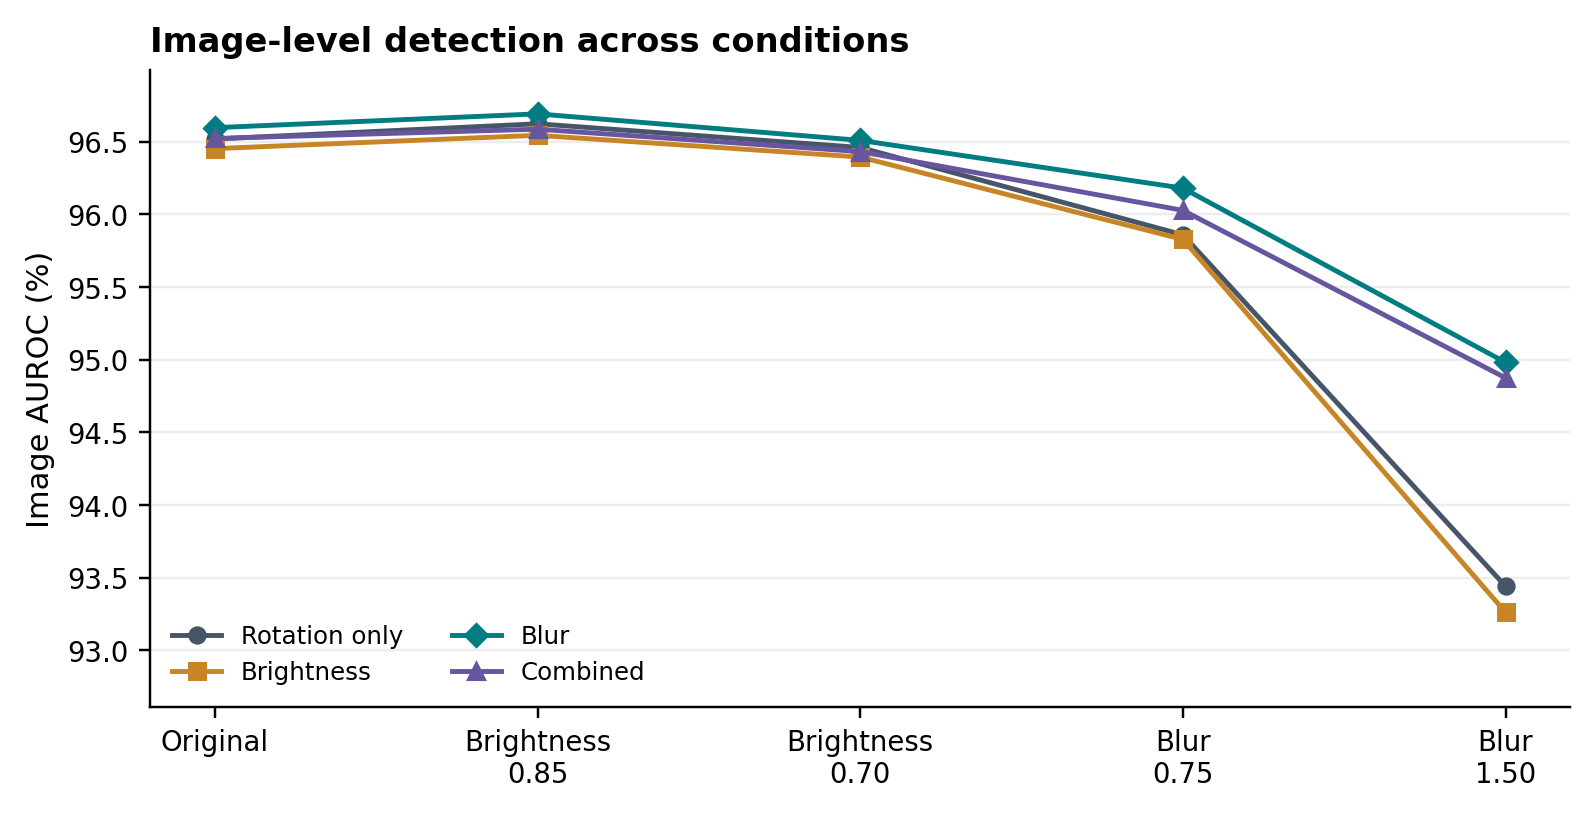

variant,rotation_only,brightness,blur,combined
condition,,,,
original,91.72,91.63,91.62,91.60
brightness_085,91.72,91.64,91.63,91.60
brightness_070,91.60,91.52,91.50,91.48
blur_075,91.24,91.14,91.20,91.18
blur_150,90.19,90.07,90.35,90.30


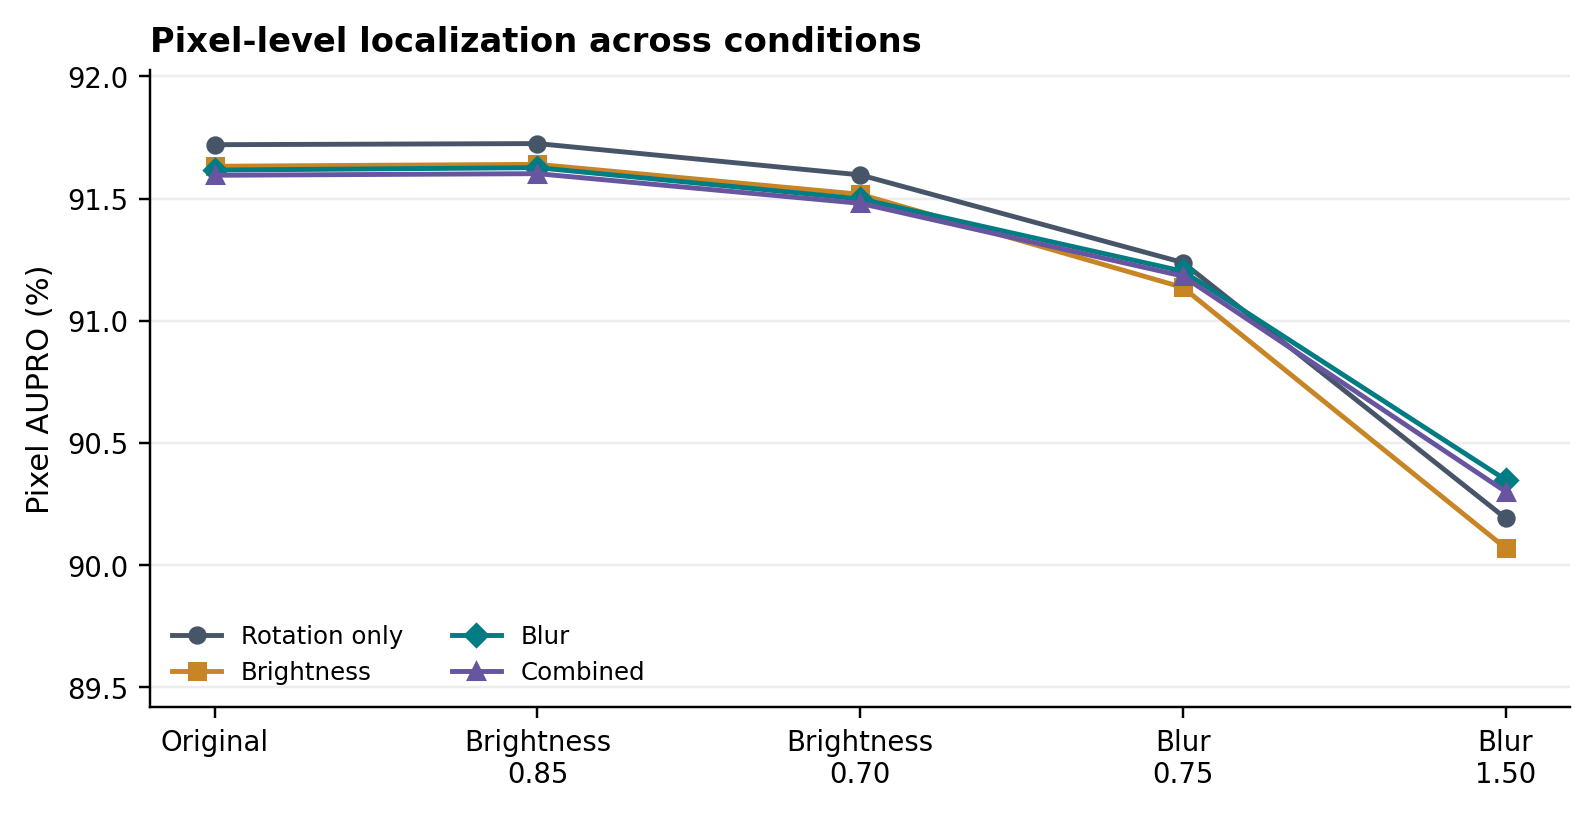

In [2]:
for metric,figure in [('image_auroc','01_ablation_image_auroc.png'),('pixel_aupro','02_ablation_pixel_aupro.png')]:
    display((100*macro.pivot(index='condition',columns='variant',values=metric).loc[conditions,variants]).round(2))
    display(Image(filename=str(FIG/figure)))


## 3. Category-level gains and reference sensitivity

,category,image_auroc_delta_pp,pixel_aupro_delta_pp
241,transistor,14.042,1.581
81,grid,2.813,0.100
261,wood,2.251,0.372
21,cable,1.568,1.482
141,metal_nut,1.189,0.442
221,toothbrush,0.463,-0.005
181,screw,0.451,0.346
41,capsule,0.266,-0.066
101,hazelnut,0.214,0.085
1,bottle,0.159,0.301


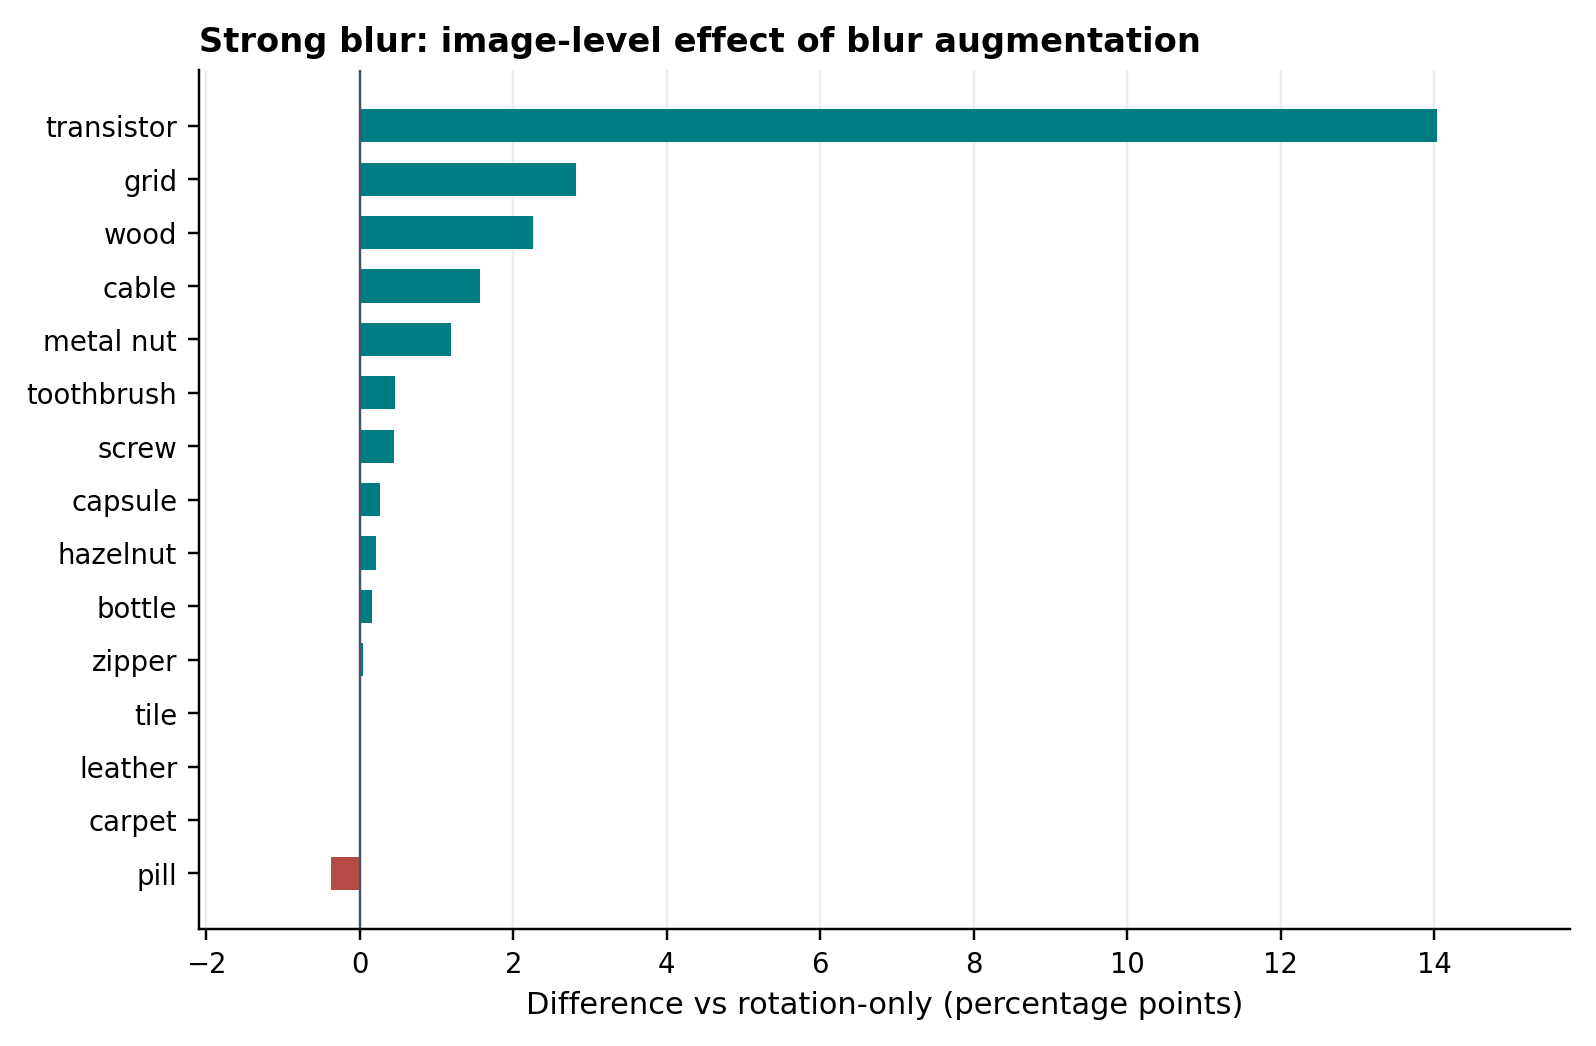

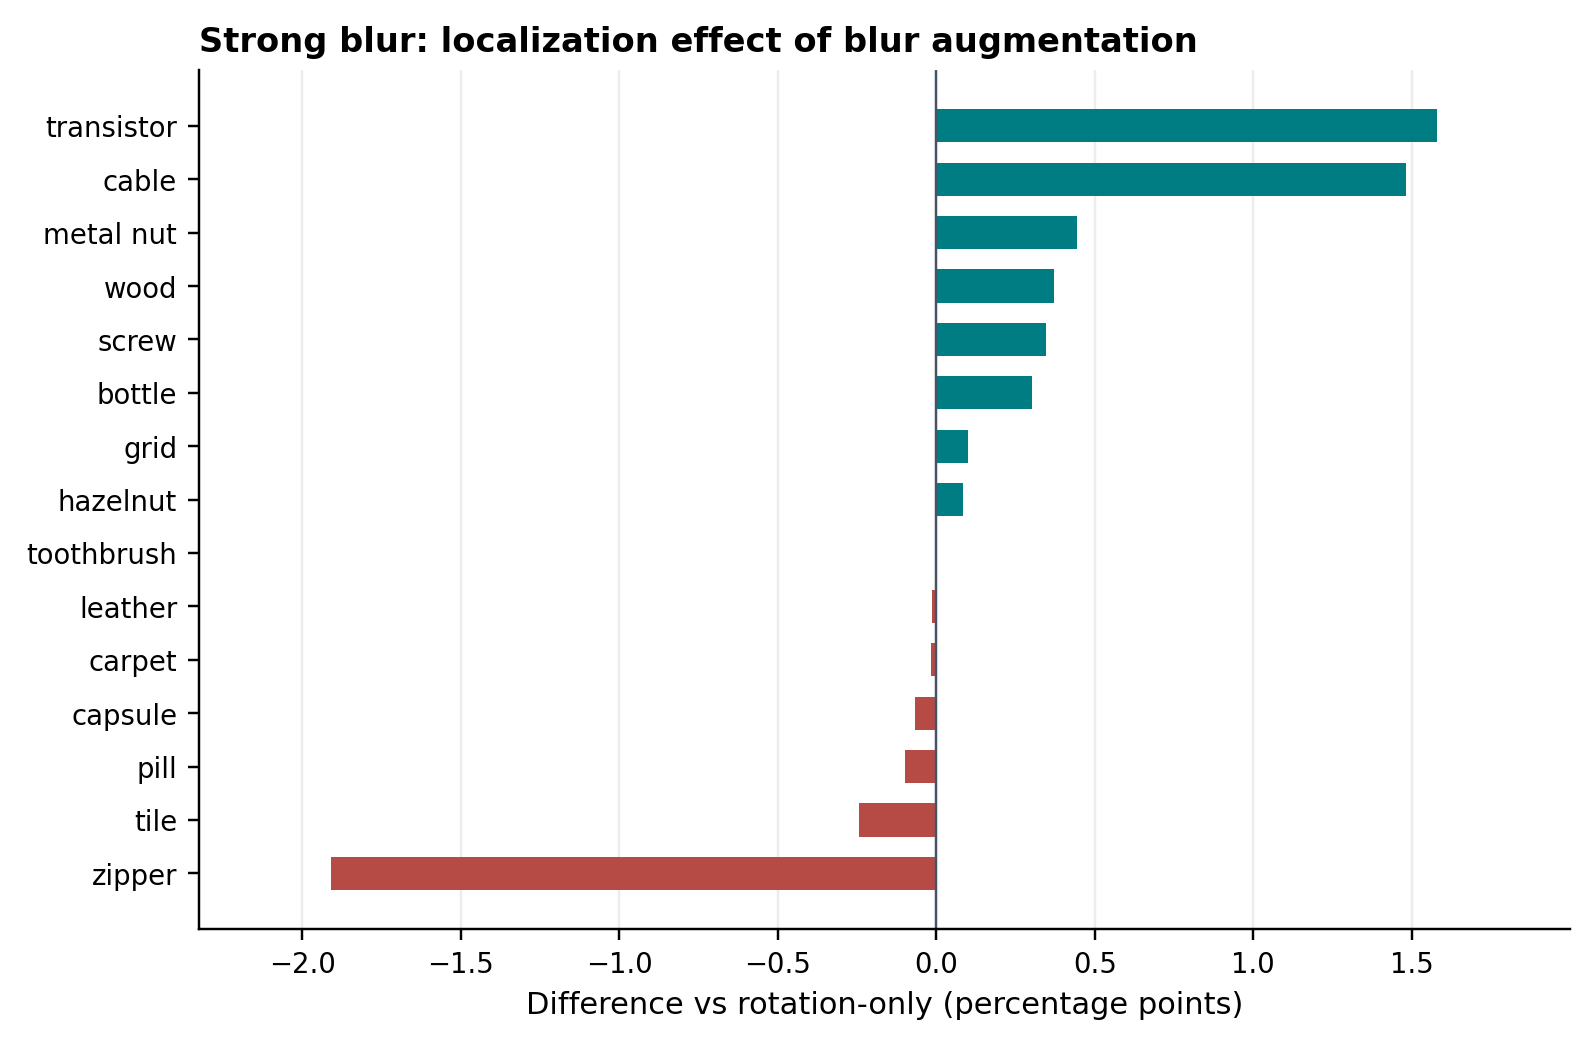

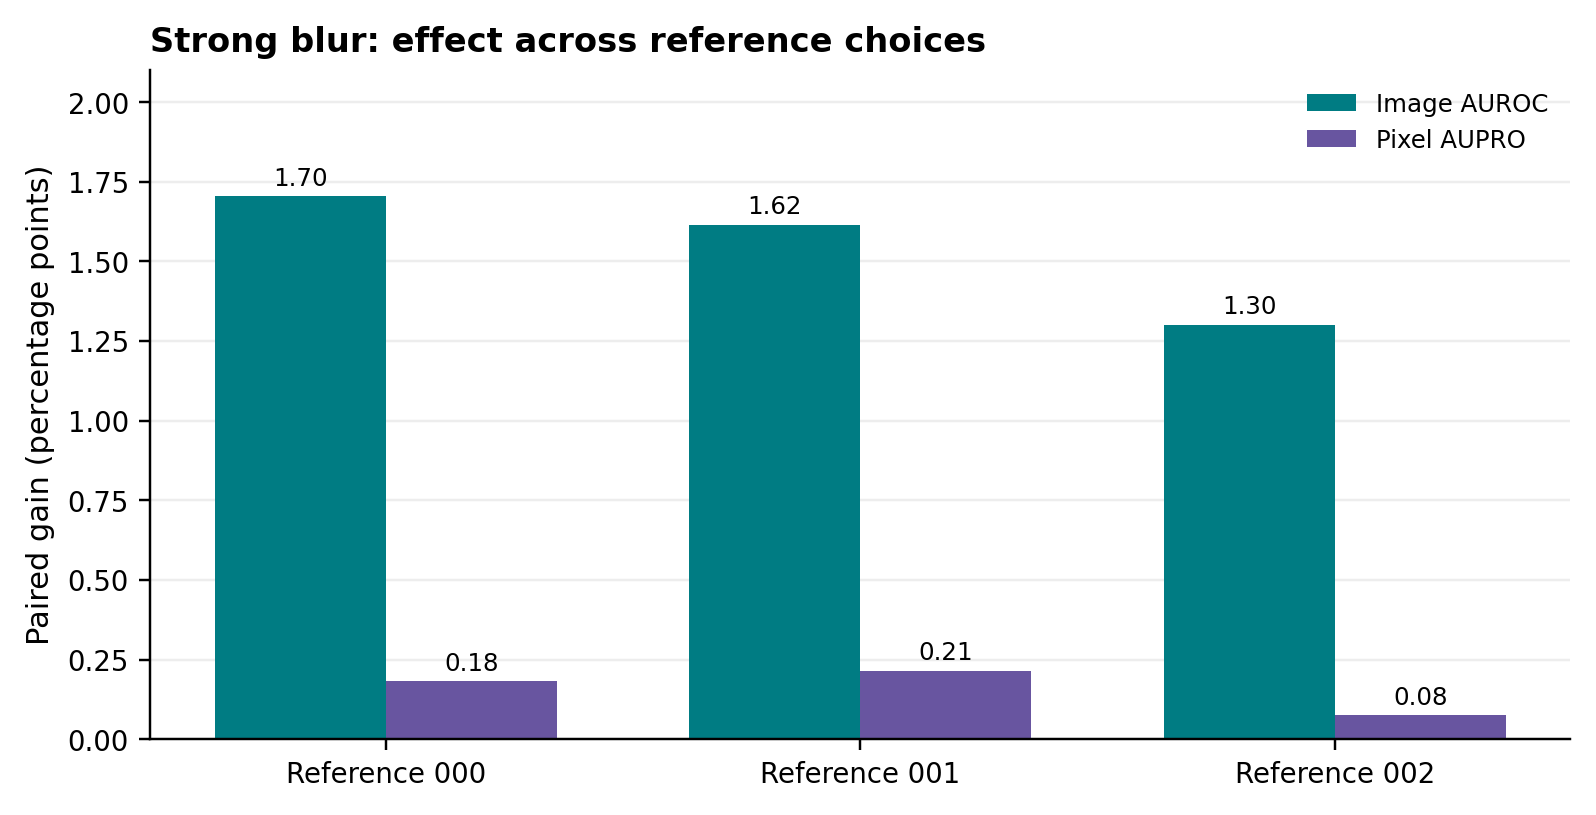

In [3]:
strong = cat[(cat.variant=='blur')&(cat.condition=='blur_150')]
display(strong[['category','image_auroc_delta_pp','pixel_aupro_delta_pp']].sort_values('image_auroc_delta_pp',ascending=False).round(3))
display(Image(filename=str(FIG/'03_strong_blur_category_image.png')))
display(Image(filename=str(FIG/'04_strong_blur_category_pixel.png')))
display(Image(filename=str(FIG/'06_reference_sensitivity.png')))


## 4. Factorial ablation and clean-relative degradation

In [4]:
interaction = pd.read_csv(REPORT/'reference_augmentation/factorial_interaction_pp.csv')
display(interaction.groupby('condition')[['image_auroc','pixel_aupro']].mean().loc[conditions].round(3))
for metric in ['image_auroc','pixel_aupro']:
    display(macro.pivot(index='condition',columns='variant',values=metric+'_robustness_gap_pp').loc[conditions,variants].round(3))


,image_auroc,pixel_aupro
condition,,
original,-0.008,0.067
brightness_085,-0.026,0.060
brightness_070,-0.011,0.061
blur_075,-0.121,0.082
blur_150,0.073,0.074


variant,rotation_only,brightness,blur,combined
condition,,,,
original,0.000,0.000,0.000,0.000
brightness_085,0.105,0.092,0.095,0.064
brightness_070,-0.058,-0.058,-0.087,-0.090
blur_075,-0.659,-0.625,-0.416,-0.495
blur_150,-3.077,-3.191,-1.615,-1.648


variant,rotation_only,brightness,blur,combined
condition,,,,
original,0.000,0.000,0.000,0.000
brightness_085,0.005,0.008,0.010,0.007
brightness_070,-0.124,-0.115,-0.118,-0.115
blur_075,-0.482,-0.496,-0.414,-0.413
blur_150,-1.528,-1.562,-1.267,-1.294


**Interpretation.** Blur augmentation yields a +1.54 pp strong-blur image AUROC gain, including a +14.04 pp Transistor gain. The pixel AUPRO gain is only +0.16 pp; clean AUPRO decreases by 0.10 pp. Brightness-only augmentation does not improve the tested aggregate endpoints consistently. Equal bank size controls cardinality, not exact patch composition. The three reference choices share test images, so the results do not establish independent-replicate significance.